In [1]:
import numpy as np
import pandas as pd

In [3]:
np.random.seed(42)


In [4]:
N = 200          # countries
T = 10           # years each
beta_true = 0.5  # the true effect we want to recover

rows = []
for i in range(N):
    alpha_i = np.random.normal(0, 1)   # hidden country trait
    for t in range(T):
        internet = 20 + 5 * alpha_i + np.random.normal(0, 2)
        income = 10 + beta_true * internet + 2 * alpha_i + np.random.normal(0, 1)
        rows.append({
            "country": f"C{i:03d}",
            "year": 2000 + t,
            "internet": internet,
            "income": income,
        })


In [5]:
df = pd.DataFrame(rows)
print(df.shape)
print(df.head(10))

(2000, 4)
  country  year   internet     income
0    C000  2000  22.207042  22.744638
1    C000  2001  25.529630  23.524090
2    C000  2002  22.015297  23.580290
3    C000  2003  24.018440  22.533174
4    C000  2004  23.568691  22.314356
5    C000  2005  21.552111  22.011446
6    C000  2006  18.657010  18.597016
7    C000  2007  21.358996  20.660095
8    C000  2008  23.112065  21.641437
9    C000  2009  19.658963  22.288559


In [6]:
from linearmodels.panel import PanelOLS, PooledOLS

df_idx = df.set_index(["country", "year"])

df_idx

internet     income
country year                      
C000    2000  22.207042  22.744638
        2001  25.529630  23.524090
        2002  22.015297  23.580290
        2003  24.018440  22.533174
        2004  23.568691  22.314356
...                 ...        ...
C199    2005  19.077203  19.116395
        2006  20.853797  17.314749
        2007  13.511746  15.574237
        2008  20.480206  17.988697
        2009  12.270341  16.020592

[2000 rows x 2 columns]

In [7]:
y = df_idx["income"]
X = df_idx[["internet"]]

pooled = PooledOLS(y, X).fit()
fe = PanelOLS(y, X, entity_effects=True).fit()

print("True beta:", beta_true)
print("Pooled OLS:", pooled.params["internet"])
print("FE:        ", fe.params["internet"])

True beta: 0.5
Pooled OLS: 0.9878337292579283
FE:         0.49896673642233424


In [8]:
n_sims = 500
pooled_estimates = []
fe_estimates = []

for s in range(n_sims):
    np.random.seed(s)
    rows = []
    for i in range(N):
        alpha_i = np.random.normal(0, 1)
        for t in range(T):
            internet = 20 + 5 * alpha_i + np.random.normal(0, 2)
            income = 10 + beta_true * internet + 2 * alpha_i + np.random.normal(0, 1)
            rows.append({"country": f"C{i:03d}", "year": 2000 + t,
                         "internet": internet, "income": income})
    sim_df = pd.DataFrame(rows).set_index(["country", "year"])
    y = sim_df["income"]
    X = sim_df[["internet"]]
    pooled_estimates.append(PooledOLS(y, X).fit().params["internet"])
    fe_estimates.append(PanelOLS(y, X, entity_effects=True).fit().params["internet"])

pooled_estimates = np.array(pooled_estimates)
fe_estimates = np.array(fe_estimates)

print("True beta:", beta_true)
print("Mean pooled:", pooled_estimates.mean())
print("Mean FE:    ", fe_estimates.mean())
print("Bias pooled:", pooled_estimates.mean() - beta_true)
print("Bias FE:    ", fe_estimates.mean() - beta_true)

True beta: 0.5
Mean pooled: 0.9895273010971483
Mean FE:     0.49998645408815995
Bias pooled: 0.48952730109714826
Bias FE:     -1.3545911840051605e-05


Saved bias_distribution.png


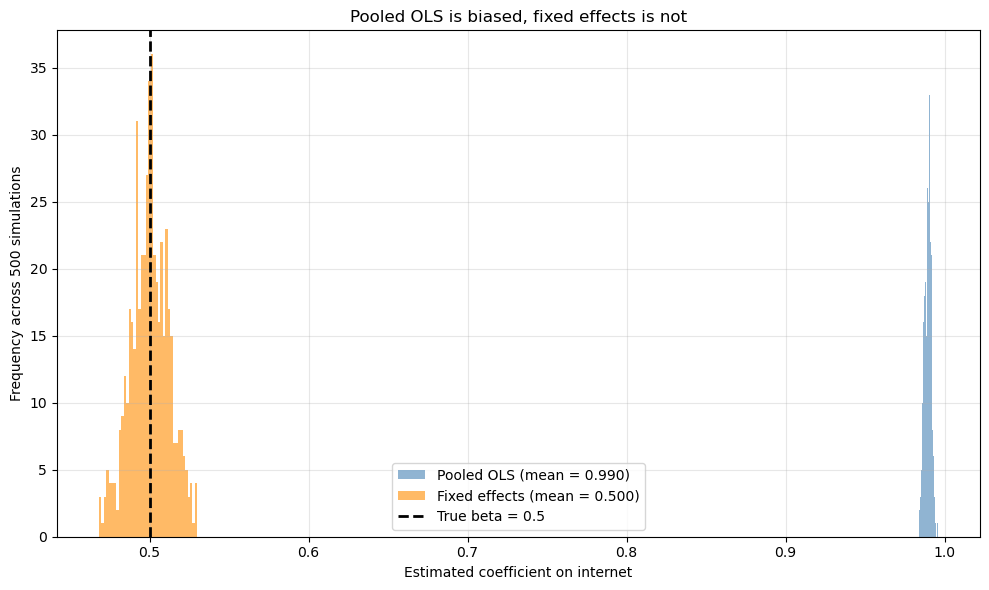

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(pooled_estimates, bins=40, alpha=0.6, color="steelblue",
        label=f"Pooled OLS (mean = {pooled_estimates.mean():.3f})")
ax.hist(fe_estimates, bins=40, alpha=0.6, color="darkorange",
        label=f"Fixed effects (mean = {fe_estimates.mean():.3f})")

ax.axvline(beta_true, color="black", linestyle="--", linewidth=2,
           label=f"True beta = {beta_true}")

ax.set_xlabel("Estimated coefficient on internet")
ax.set_ylabel("Frequency across 500 simulations")
ax.set_title("Pooled OLS is biased, fixed effects is not")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("bias_distribution.png", dpi=150)
print("Saved bias_distribution.png")